# 5 · Diffusion + proliferation + irrigation — corrected

Corrected version of [`original/notebooks/05-diffusion-proliferation-irrigation.ipynb`](../../original/notebooks/05-diffusion-proliferation-irrigation.ipynb). The original is kept unchanged.

**Model** — tumour density $n$ coupled to vessel density $V$:

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n + \big[\alpha_0 + \alpha_1\,(V - 1)^{\Gamma}\big]\, n\left(1 - \frac{n}{N_{\max}}\right)$$

$$\frac{\partial V}{\partial t} = \beta(x)\, n\, V \left(1 - \frac{V}{V_{\max}}\right)$$

These are the equations from the course notes ([`original/course-notes/07-vessel-model-and-gamma.jpg`](../../original/course-notes/07-vessel-model-and-gamma.jpg)), where $\Gamma$ is described as "how functional the irrigation is" (values 0, 0.5 and 1 are tried there). Vessels grow where there are tumour cells, up to $V_{\max}$, and more vessels raise the local growth rate of the tumour. $\beta$ is $0.001$ on the left half of the grid and $0.1$ on the right half, so vessels form about 100× faster on the right. There the growth rate rises from $\alpha_0 = 1$ towards $\alpha_0 + \alpha_1 (V_{\max} - 1)^{\Gamma} = 1 + \sqrt{3} \approx 2.73$.

**What changed from the original**

- **Brackets in the tumour equation.** The original update was `delta_t * ((D / delta_x**2) * (laplacian + rate*n) * (1 - n/N_Max))`. This multiplied the growth term by $D = 0.2$, and also multiplied the *diffusion* term by $(1 - n/N_{\max})$, switching diffusion off wherever the tumour is dense. Each term is now separate, as in the equation above.
- **Equations now follow the course notes.** The original code used `Alpha_one * (V**Gamma - 1)` and `Beta * n * (1 - V/V_max)`. The notes write $\alpha_1 (V - 1)^{\Gamma}$ and $\beta\, n\, V\,(1 - V/V_{\max})$. Both forms are zero where no new vessels have formed ($V = 1$). With the notes' form, a fully vascularised region gets a larger boost (about 1.73 instead of 1 at $V_{\max} = 4$), and vessels grow faster because their growth is proportional to $V$.
- Both fields are still updated simultaneously from the previous step.
- **Initial cutoff** (see the comment in the initial-condition cell).
- NumPy array operations instead of nested loops; one combined figure instead of 20 separate ones.

In [1]:
import sys
sys.path.insert(0, "..")    # shared code lives in corrected/angiogenesis.py
import numpy as np
import matplotlib.pyplot as plt
from angiogenesis import laplacian, three_regions, check_stability, plot_snapshots

In [2]:
# Parameters (same as the original)
l = 200
A = 0.05
σ1, σ2, σ3 = 15, 25, 12
delta_t = 0.1
delta_x = 1
D = 0.2
Alpha_zero = 1
Alpha_one = 1
Gamma = 0.5
V_max = 4
N_Max = 1
cutoff = 1e-3     # new, see below
num_steps = 1000
save_steps = [100, 300, 500, 700, 1000]

check_stability(D, delta_t, delta_x)   # explicit scheme needs D*dt/dx^2 <= 1/4

In [3]:
n = three_regions(l, A, (σ1, σ2, σ3))   # same three Gaussian regions as the original notebook

# A Gaussian is never exactly zero. With logistic growth, even its 1e-30 tails
# grow exponentially and the whole grid fills up "spontaneously" within a few
# hundred steps. Treat densities below the cutoff as "no tumour cells".
n[n < cutoff] = 0.0

V = np.ones((l, l))               # uniform initial vessel density
Beta = np.zeros((l, l))
Beta[:, : l // 2] = 0.001         # left half: slow vessel growth
Beta[:, l // 2 :] = 0.1           # right half: fast vessel growth

In [4]:
tumour_frames, vessel_frames = {}, {}
for step in range(1, num_steps + 1):
    growth_rate = Alpha_zero + Alpha_one * (V - 1)**Gamma    # V >= 1 always
    n_next = n + delta_t * (D * laplacian(n, delta_x) + growth_rate * n * (1 - n / N_Max))
    V_next = V + delta_t * Beta * n * V * (1 - V / V_max)
    n, V = n_next, V_next
    if step in save_steps:
        tumour_frames[step] = n.copy()
        vessel_frames[step] = V.copy()

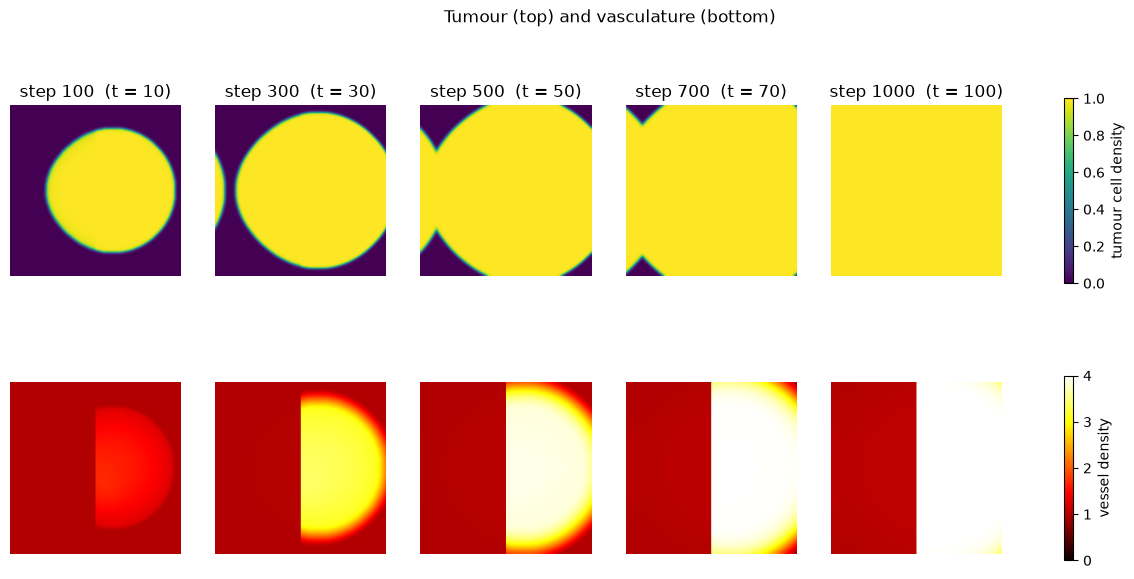

In [5]:
fig, axes = plt.subplots(2, len(save_steps), figsize=(3.2 * len(save_steps), 6.6))
for col, step in enumerate(save_steps):
    im_n = axes[0, col].imshow(tumour_frames[step], origin="lower", cmap="viridis", vmin=0, vmax=N_Max)
    im_v = axes[1, col].imshow(vessel_frames[step], origin="lower", cmap="hot", vmin=0, vmax=V_max)
    axes[0, col].set_title(f"step {step}  (t = {step * delta_t:g})")
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(im_n, ax=axes[0], shrink=0.8, label="tumour cell density")
fig.colorbar(im_v, ax=axes[1], shrink=0.8, label="vessel density")
fig.suptitle("Tumour (top) and vasculature (bottom)")
plt.show()

**Reading the result.** Vessels build up only where the tumour is, and on the right they reach $V_{\max}$ by about step 500. But the tumour spreads at almost the same speed on both sides. Re-running with $\beta = 0$ everywhere changes the tumour area by less than 1 % (17,114 vs 17,000 cells above density 0.5 at step 100; 35,122 vs 35,043 at step 500).

The reason is in the equations. The front is pushed forward by the sparse cells at its leading edge, where no vessels have formed yet ($V \approx 1$, so the growth rate is just $\alpha_0$). Behind the front, where vessels do accumulate, the tumour is already at $N_{\max}$, so $n(1 - n/N_{\max}) \approx 0$ and a higher growth rate changes nothing.

For the vasculature to matter, it has to act where the tumour is not yet saturated: for example vessels that grow or spread into tissue ahead of the front, or a carrying capacity that depends on the nutrient supply ($N_{\max}$ as a function of $V$).